# 3. Análisis de la variable objetivo (2.1)

Frecuencia de cada clase, grado de desbalance, casos de la clase minoritaria,
comportamiento en el tiempo y en el espacio, y consecuencias para la métrica y la
validación. Solo entrenamiento.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

train = load_train()
y = train[TARGET]

,líneas,%,pedidos,% pedidos
clase,,,,
1 · tardía,78549,54.9,26164,54.83
0 · no tardía,64526,45.1,21555,45.17


- Razón de desbalance (mayoritaria/minoritaria): **1,22**.
- Clase minoritaria: **0 (no tardía)** con 64.526 líneas y 21.555 pedidos. A nivel de pedido la proporción es prácticamente la misma (54,8 % tardíos), así que el tamaño del pedido no se asocia con la etiqueta.
- Una regla trivial que siempre predice «tardía» acierta 54,9 %: ese es el piso de accuracy que el modelo debe superar.

late_delivery_risk,0,1,All
delivery_status,,,
Advance shipping,32954,0,32954
Late delivery,0,78549,78549
Shipping canceled,6032,0,6032
Shipping on time,25540,0,25540
All,64526,78549,143075


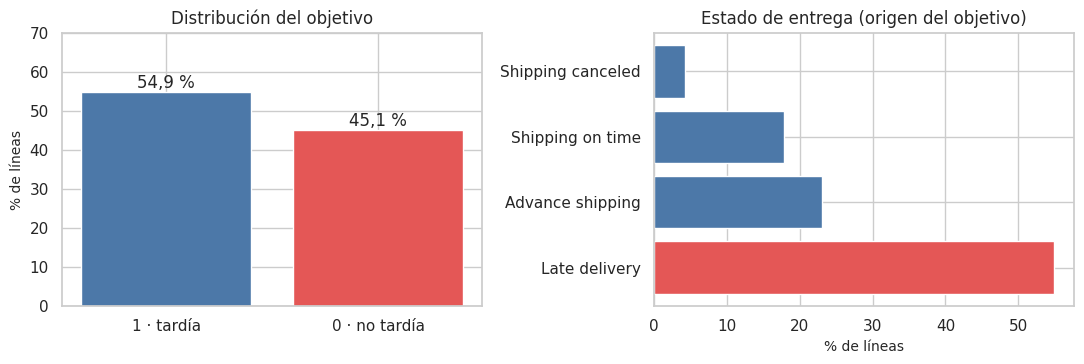

In [2]:
dist = (y.value_counts().rename_axis("clase").to_frame("líneas")
        .assign(**{"%": lambda d: 100 * d["líneas"] / d["líneas"].sum()}))
por_pedido = train.groupby(ORDER_COL)[TARGET].first().value_counts()
dist["pedidos"] = por_pedido.reindex(dist.index).to_numpy()
dist["% pedidos"] = 100 * dist["pedidos"] / dist["pedidos"].sum()
dist.index = dist.index.map({0: "0 · no tardía", 1: "1 · tardía"})
dist.to_csv(TABLES / "objetivo_distribucion.csv")
display(dist.round(2))
ratio = dist["líneas"].max() / dist["líneas"].min()
md_out(f"- Razón de desbalance (mayoritaria/minoritaria): **{es(ratio, 2)}**.\n"
       f"- Clase minoritaria: **0 (no tardía)** con {es(int(dist['líneas'].min()), 0)} líneas y {es(int(dist['pedidos'].min()), 0)} pedidos. "
       f"A nivel de pedido la proporción es prácticamente la misma ({es(dist['% pedidos'].max() / 100, 1, pct=True)} tardíos), así que el tamaño del pedido no se asocia con la etiqueta.\n"
       f"- Una regla trivial que siempre predice «tardía» acierta {es(y.mean(), 1, pct=True)}: ese es el piso de accuracy que el modelo debe superar.")

origen = pd.crosstab(train["delivery_status"], y, margins=True)
display(origen)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(dist.index, dist["%"], color=["#4c78a8", "#e45756"])
for i, v in enumerate(dist["%"]):
    axes[0].text(i, v + 1, es(v / 100, 1, pct=True), ha="center")
axes[0].set_ylabel("% de líneas"); axes[0].set_title("Distribución del objetivo"); axes[0].set_ylim(0, 70)
ds = train["delivery_status"].value_counts(normalize=True) * 100
axes[1].barh(ds.index, ds.values, color=["#e45756" if s == "Late delivery" else "#4c78a8" for s in ds.index])
axes[1].set_xlabel("% de líneas"); axes[1].set_title("Estado de entrega (origen del objetivo)")
plt.tight_layout(); save_figure(fig, "03_distribucion_objetivo.png"); plt.show()

**Interpretación.** El objetivo es binario y **moderadamente balanceado**
(≈ 55 % tardías). La etiqueta proviene de `delivery_status`: «Late delivery» → 1;
«Advance shipping», «Shipping on time» y «Shipping canceled» → 0. La clase 0 mezcla
dos situaciones distintas: entregas puntuales y **pedidos que nunca se
entregaron** (cancelados o sospechosos de fraude); esto se resuelve en el capítulo 9.

## Relación con las predictoras principales

Vista rápida de la tasa de entregas tardías por las categóricas con más señal
(el análisis completo, con pruebas y tamaños de efecto, está en el capítulo 5).

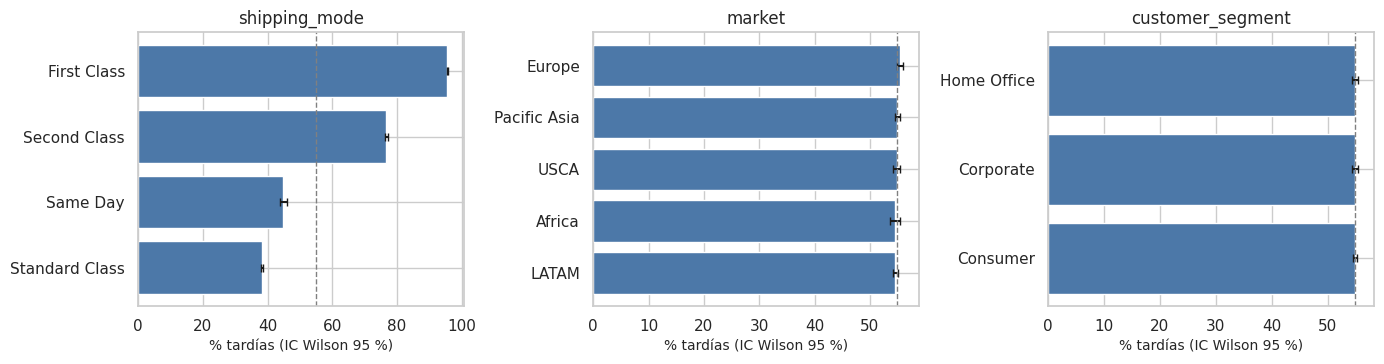

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["shipping_mode", "market", "customer_segment"]):
    t = rate_table(train[col], y).sort_values("tasa")
    ax.barh(t["categoria"], 100 * t["tasa"], xerr=[100 * (t["tasa"] - t["ic_inf"]), 100 * (t["ic_sup"] - t["tasa"])],
            color="#4c78a8", capsize=3)
    ax.axvline(100 * y.mean(), color="gray", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("% tardías (IC Wilson 95 %)")
plt.tight_layout(); save_figure(fig, "03_objetivo_por_categoria.png"); plt.show()

**Interpretación.** El **modo de envío** domina: First Class llega tarde en ≈ 95 %
de los casos y Standard Class en ≈ 38 %. En cambio, mercado y segmento de cliente
apenas mueven la tasa (diferencias < 1 punto). Es la primera señal de que el
problema sin fuga tiene **una predictora fuerte y mucho ruido**.

## Comportamiento en el tiempo y en el espacio

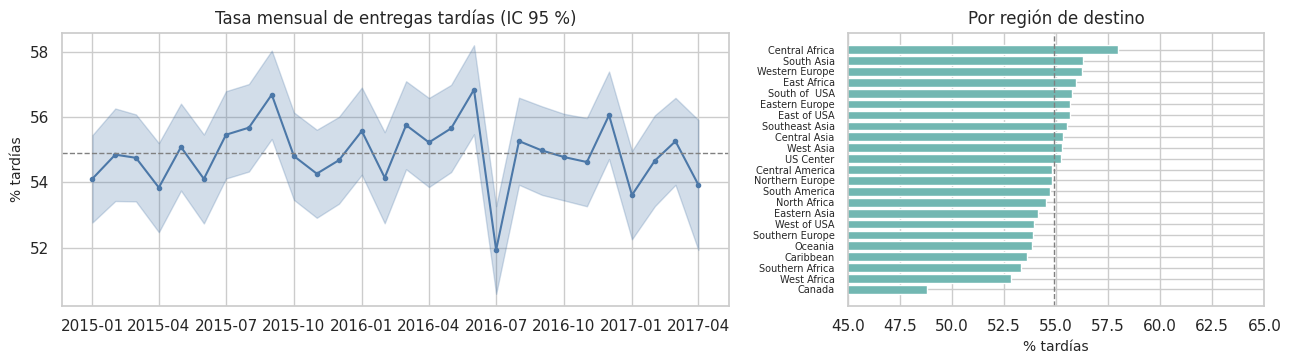

Tasa mensual entre **51,9 %** y **56,8 %**; por región de destino entre **48,8 %** y **58,0 %**.

In [4]:
mensual = train.groupby(train[DATE_COL].dt.to_period("M"))[TARGET].agg(["sum", "count"])
lo, hi = wilson_interval(mensual["sum"], mensual["count"])
mensual["tasa"] = mensual["sum"] / mensual["count"]
x = mensual.index.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].fill_between(x, 100 * lo, 100 * hi, alpha=0.25, color="#4c78a8")
axes[0].plot(x, 100 * mensual["tasa"], marker="o", ms=3, color="#4c78a8")
axes[0].axhline(100 * y.mean(), color="gray", ls="--", lw=1)
axes[0].set_ylabel("% tardías"); axes[0].set_title("Tasa mensual de entregas tardías (IC 95 %)")
reg = rate_table(train["order_region"], y).sort_values("tasa")
axes[1].barh(reg["categoria"], 100 * reg["tasa"], color="#72b7b2")
axes[1].axvline(100 * y.mean(), color="gray", ls="--", lw=1)
axes[1].set_xlim(45, 65); axes[1].set_xlabel("% tardías"); axes[1].set_title("Por región de destino")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); save_figure(fig, "03_objetivo_tiempo_espacio.png"); plt.show()
md_out(f"Tasa mensual entre **{es(mensual['tasa'].min(), 1, pct=True)}** y **{es(mensual['tasa'].max(), 1, pct=True)}**; "
       f"por región de destino entre **{es(reg['tasa'].min(), 1, pct=True)}** y **{es(reg['tasa'].max(), 1, pct=True)}**.")

**Interpretación.** La tasa es **estable en el tiempo** (fluctúa dentro de los
intervalos de confianza alrededor del 55 %) y casi **homogénea entre regiones**.
Los capítulos 7 y 8 lo comprueban formalmente (estacionariedad, autocorrelación
temporal y espacial).

## Implicaciones para la métrica y la validación

- **Métrica:** con clases cercanas a 55/45, accuracy no es engañosa, pero depende del
  umbral. Se usa **ROC-AUC** como métrica principal porque mide la capacidad de
  **ordenar** pedidos por riesgo (el uso previsto) y es independiente del umbral y de
  la prevalencia. Se complementa con Average Precision, F1, recall,
  matriz de confusión, Brier y calibración.
- **Línea base:** `DummyClassifier` (prior) tiene ROC-AUC = 0,5 y accuracy ≈ 55 %.
- **Validación:** estratificar no es necesario (prevalencia estable), pero sí
  respetar el **tiempo** (cronológica con *gap*) y los **pedidos** (no separar
  líneas de un mismo pedido; bootstrap por pedido).